In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/python_sales_analysis_dataset.csv')

print(df.head())

   order_id  order_date       city     product     category  quantity  \
0     10001  2025-12-15   Shymkent     Pen Set   Stationery       5.0   
1     10002  2025-08-03   Shymkent  Smartphone  Electronics       3.0   
2     10003  2025-12-26   Shymkent        Desk    Furniture       5.0   
3     10004  2025-07-11  Karaganda    Notebook   Stationery       5.0   
4     10005  2025-09-10  Karaganda    Notebook   Stationery       1.0   

   unit_price  discount  unit_cost payment_method  
0          12      0.00          5          Kaspi  
1         520      0.15        380           Cash  
2         180      0.05        110  Bank Transfer  
3           5      0.00          2  Bank Transfer  
4           5      0.00          2          Kaspi  


In [ ]:
print("Кестенің өлшемі:")
print(df.shape)

Кестенің өлшемі:
(1200, 10)


In [ ]:
print(df.columns)

Index(['order_id', 'order_date', 'city', 'product', 'category', 'quantity',
       'unit_price', 'discount', 'unit_cost', 'payment_method'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        1200 non-null   int64  
 1   order_date      1200 non-null   object 
 2   city            1197 non-null   object 
 3   product         1200 non-null   object 
 4   category        1200 non-null   object 
 5   quantity        1198 non-null   float64
 6   unit_price      1200 non-null   int64  
 7   discount        1198 non-null   float64
 8   unit_cost       1200 non-null   int64  
 9   payment_method  1200 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 93.9+ KB


In [ ]:
print(df.isnull().sum())

order_id          0
order_date        0
city              3
product           0
category          0
quantity          2
unit_price        0
discount          2
unit_cost         0
payment_method    0
dtype: int64


In [ ]:
# Қала атауы жоқ жерлерді Unknown деп толтыру
df['city'] = df['city'].fillna('Unknown')

# Тауар саны жоқ жерлерді 1 деп толтыру
df['quantity'] = df['quantity'].fillna(1)

# Жеңілдік жоқ жерлерді 0 деп толтыру
df['discount'] = df['discount'].fillna(0)

In [ ]:
print(df.isnull().sum())

order_id          0
order_date        0
city              0
product           0
category          0
quantity          0
unit_price        0
discount          0
unit_cost         0
payment_method    0
dtype: int64


In [ ]:
df['total_sales'] = (
    df['quantity'] *
    df['unit_price'] *
    (1 - df['discount'])
)

df['total_profit'] = (
    df['quantity'] *
    (df['unit_price'] * (1 - df['discount']) - df['unit_cost'])
)

print(df.head())

   order_id  order_date       city     product     category  quantity  \
0     10001  2025-12-15   Shymkent     Pen Set   Stationery       5.0   
1     10002  2025-08-03   Shymkent  Smartphone  Electronics       3.0   
2     10003  2025-12-26   Shymkent        Desk    Furniture       5.0   
3     10004  2025-07-11  Karaganda    Notebook   Stationery       5.0   
4     10005  2025-09-10  Karaganda    Notebook   Stationery       1.0   

   unit_price  discount  unit_cost payment_method  total_sales  total_profit  
0          12      0.00          5          Kaspi         60.0          35.0  
1         520      0.15        380           Cash       1326.0         186.0  
2         180      0.05        110  Bank Transfer        855.0         305.0  
3           5      0.00          2  Bank Transfer         25.0          15.0  
4           5      0.00          2          Kaspi          5.0           3.0  


In [ ]:
print("Жалпы сатылым:", df['total_sales'].sum())
print("Жалпы пайда:", df['total_profit'].sum())
print("Орташа сатылым:", df['total_sales'].mean())

Жалпы сатылым: 641059.6
Жалпы пайда: 172228.6
Орташа сатылым: 534.2163333333333


In [ ]:
top_products = df.groupby('product')['quantity'].sum()

top_products = top_products.sort_values(ascending=False)

print(top_products.head(5))

product
Smartphone    471.0
Headphones    416.0
Pen Set       411.0
Watch         402.0
Chair         394.0
Name: quantity, dtype: float64


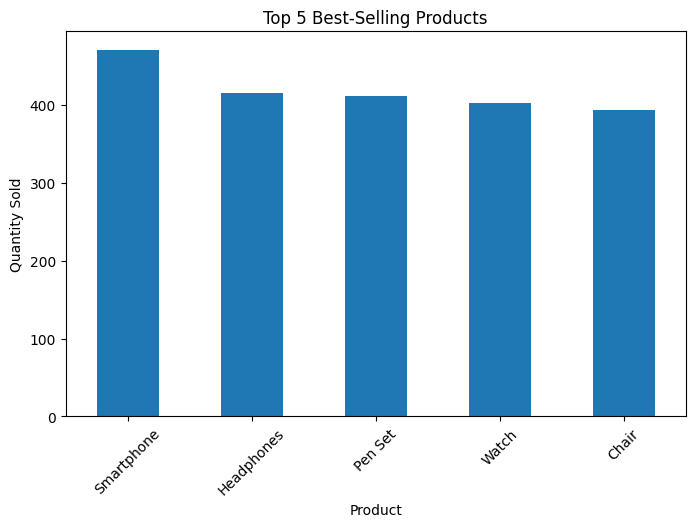

In [ ]:
import matplotlib.pyplot as plt

top_products.head(5).plot(kind='bar', figsize=(8, 5))

plt.title('Top 5 Best-Selling Products')
plt.xlabel('Product')
plt.ylabel('Quantity Sold')
plt.xticks(rotation=45)
plt.show()

In [ ]:
city_sales = df.groupby('city')['total_sales'].sum()

city_sales = city_sales.sort_values(ascending=False)

print(city_sales)

city
Shymkent     141618.65
Aktobe       131099.60
Karaganda    129333.90
Astana       125527.30
Almaty       112977.90
Unknown         502.25
Name: total_sales, dtype: float64


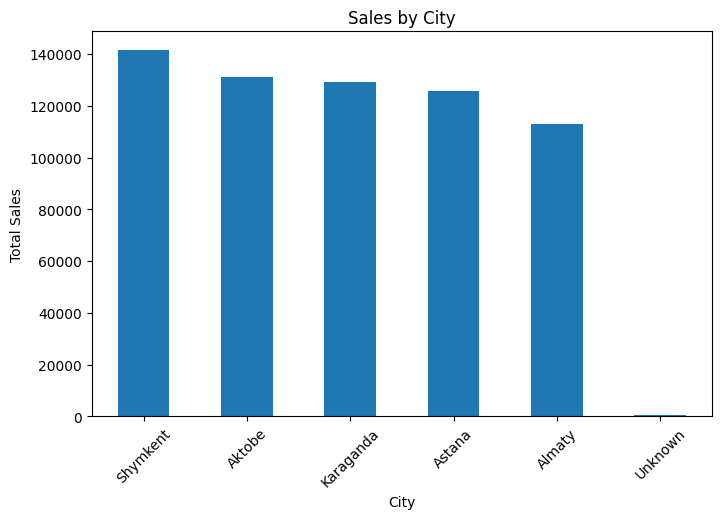

In [ ]:
city_sales.plot(kind='bar', figsize=(8, 5))

plt.title('Sales by City')
plt.xlabel('City')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

In [ ]:
df['order_date'] = pd.to_datetime(df['order_date'])

In [ ]:
df['month'] = df['order_date'].dt.month

monthly_sales = df.groupby('month')['total_sales'].sum()

print(monthly_sales)

month
1     58766.20
2     46683.25
3     56427.70
4     63193.15
5     43844.55
6     57620.75
7     59049.55
8     70158.65
9     44700.25
10    43059.75
11    40117.95
12    57437.85
Name: total_sales, dtype: float64


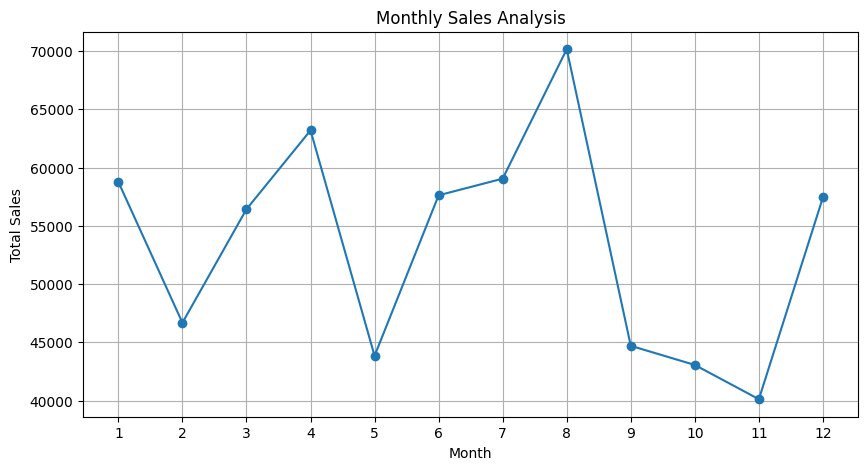

In [ ]:
monthly_sales.plot(kind='line', marker='o', figsize=(10, 5))

plt.title('Monthly Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

In [ ]:
best_month = monthly_sales.idxmax()
best_sales = monthly_sales.max()

print("Ең жақсы ай:", best_month)
print("Сатылым сомасы:", round(best_sales, 2))

Ең жақсы ай: 8
Сатылым сомасы: 70158.65


In [ ]:
print("TOTAL ORDERS:", df['order_id'].nunique())

print("TOTAL SALES:", round(df['total_sales'].sum(), 2))

print("TOTAL PROFIT:", round(df['total_profit'].sum(), 2))

print("AVERAGE ORDER VALUE:", round(df['total_sales'].mean(), 2))

print("TOTAL PRODUCTS SOLD:", df['quantity'].sum())

TOTAL ORDERS: 1200
TOTAL SALES: 641059.6
TOTAL PROFIT: 172228.6
AVERAGE ORDER VALUE: 534.22
TOTAL PRODUCTS SOLD: 3586.0


In [ ]:
product_profit = df.groupby('product')['total_profit'].sum()

product_profit = product_profit.sort_values(ascending=False)

print(product_profit)

product
Smartphone    46544.0
Laptop        45837.5
Desk          21823.0
Watch         18574.0
Headphones    14495.0
Chair         13014.5
Backpack       8435.6
Pen Set        2547.0
Notebook        958.0
Name: total_profit, dtype: float64


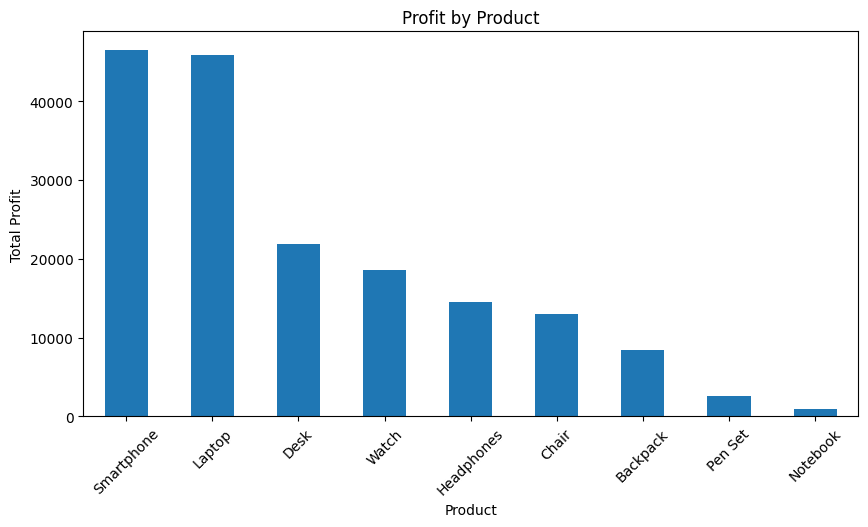

In [ ]:
product_profit.plot(kind='bar', figsize=(10, 5))

plt.title('Profit by Product')
plt.xlabel('Product')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.show()

In [ ]:
best_product = product_profit.idxmax()
best_city = city_sales.idxmax()
best_month = monthly_sales.idxmax()

print("BUSINESS INSIGHTS")
print("----------------------")

print("Best Product:", best_product)
print("Best City:", best_city)
print("Best Month:", best_month)

BUSINESS INSIGHTS
----------------------
Best Product: Smartphone
Best City: Shymkent
Best Month: 8


In [ ]:
import os

os.makedirs('project_results', exist_ok=True)


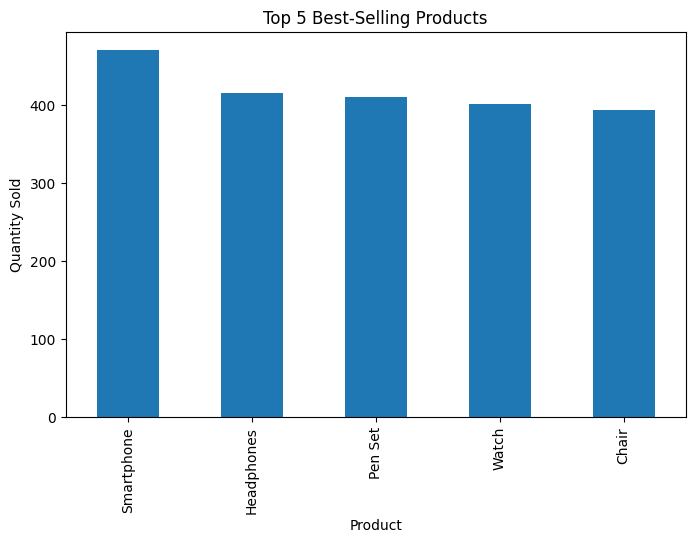

In [ ]:
top_products.head(5).plot(kind='bar', figsize=(8, 5))

plt.title('Top 5 Best-Selling Products')
plt.xlabel('Product')
plt.ylabel('Quantity Sold')

plt.savefig('project_results/top_products.png',
            bbox_inches='tight')

plt.show()

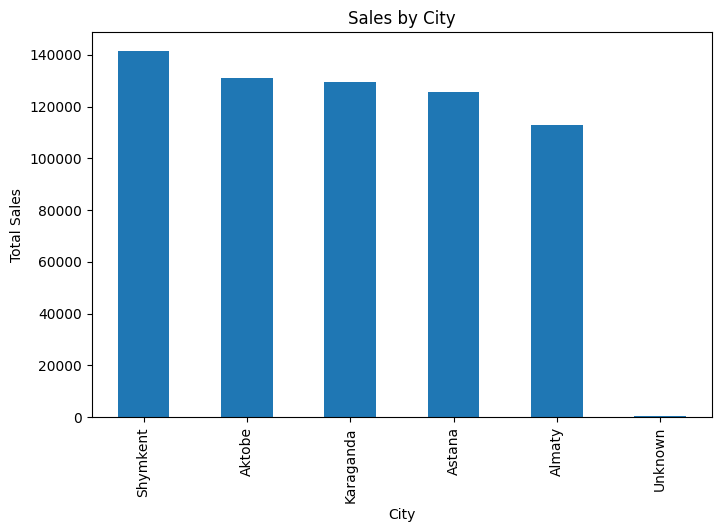

In [ ]:
city_sales.plot(kind='bar', figsize=(8, 5))

plt.title('Sales by City')
plt.xlabel('City')
plt.ylabel('Total Sales')

plt.savefig('project_results/sales_by_city.png',
            bbox_inches='tight')

plt.show()

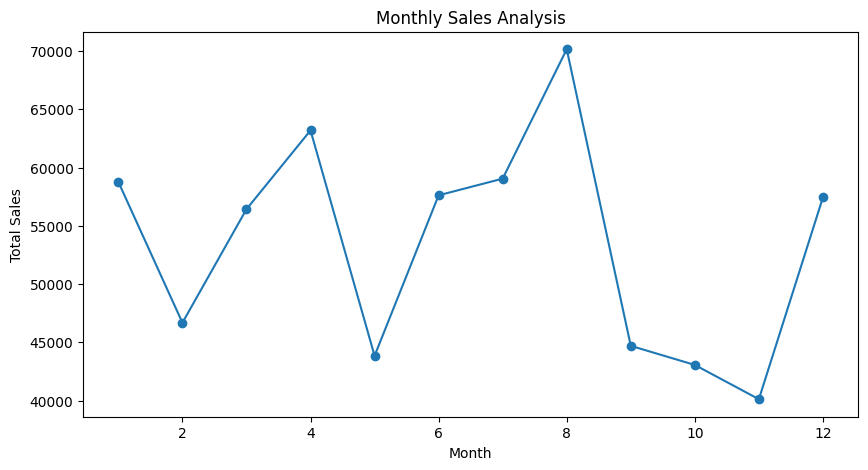

In [ ]:
monthly_sales.plot(kind='line', marker='o', figsize=(10, 5))

plt.title('Monthly Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.savefig('project_results/monthly_sales.png',
            bbox_inches='tight')

plt.show()

In [ ]:
df.to_csv('project_results/cleaned_sales_data.csv',
          index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
report = f"""
PYTHON SALES DATA ANALYSIS

Total Orders: {df['order_id'].nunique()}
Total Sales: {df['total_sales'].sum():.2f}
Total Profit: {df['total_profit'].sum():.2f}
Average Order Value: {df['total_sales'].mean():.2f}
Total Products Sold: {df['quantity'].sum()}

Best Product: {product_profit.idxmax()}
Best City: {city_sales.idxmax()}
Best Month: {monthly_sales.idxmax()}

Tools:
Python, Pandas, Matplotlib, Google Colab

Dataset:
Synthetic sample data for educational purposes.
"""

with open('project_results/analysis_report.txt', 'w') as file:
    file.write(report)

print(report)


PYTHON SALES DATA ANALYSIS

Total Orders: 1200
Total Sales: 641059.60
Total Profit: 172228.60
Average Order Value: 534.22
Total Products Sold: 3586.0

Best Product: Smartphone
Best City: Shymkent
Best Month: 8

Tools:
Python, Pandas, Matplotlib, Google Colab

Dataset:
Synthetic sample data for educational purposes.



In [ ]:
import shutil

shutil.make_archive(
    'Python_Sales_Analysis',
    'zip',
    'project_results'
)

print("Project ZIP created successfully!")

Project ZIP created successfully!


In [ ]:
from google.colab import files

files.download('Python_Sales_Analysis.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>